In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

In [2]:
import os
import random
import numpy as np
import torch
def seed_everything(seed=42):

    os.environ["PYTHONHASHSEED"] = str(seed)

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

    torch.use_deterministic_algorithms(True,warn_only=True)


seed_everything(42)

In [3]:
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, classification_report, roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from torch.utils.data import DataLoader
from torchvision import transforms
from matplotlib import pyplot as plt
import torch.optim as optim
import seaborn as sns
import torch.nn as nn
import numpy as np
import cv2 as cv
import random
import torch
import os

from domain.mvcnn_dataset import MVCNNDataset
from domain.mvcnn_model import MVCNNModel
from domain.history_model import HistoryModel
from domain.mvcnn_grad_cam import MVCNNGradCAM

Objeto para salvar histórico do modelo (dados de treinamento, validação e teste)

In [4]:
history = HistoryModel()

In [5]:
def listar_diretorio(path):
    return [os.path.join(path, path_image) for path_image in os.listdir(path)]

Convertendo classes textuais em valor numérico

In [6]:
classes_shrimp = ["P. brasiliensis", "P. isabelae", "P. paulensis", "P. subtilis"]

class_to_idx = [
    i for i in range(0, len(classes_shrimp))
]
print(class_to_idx)

class_to_idx = {
    cls: i for i, cls in enumerate(classes_shrimp)
}

[0, 1, 2, 3]


Guardando Dataset

In [7]:
from pathlib import Path

views_list_image_paths = []
labels_paths = []
for path in Path("../dataset_segmentation_cinza/").iterdir():

    if path.is_dir():
        label = path.name
        
        for class_dir in path.iterdir():

            if class_dir.iterdir():
                views_list_image_paths.append(listar_diretorio(class_dir))
                labels_paths.append(label)

print(len(views_list_image_paths))
print(len(labels_paths))

199
199


Tranformers de treinamento aplicando DataArgumentation

In [8]:
train_transform = transforms.Compose([ # Aplicando data argumentation na base de treino e aplicando transformadores para padronizar as imagens
    transforms.Resize((256,256)), # reduzindo tamanho das imagens

    transforms.RandomResizedCrop(
        224,
        scale=(0.8,1.0)
    ),

    transforms.RandomHorizontalFlip(p=0.5), # rotacionando imagens

    transforms.RandomRotation(15),# rotacionaod imagens

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize( # Normalizando dados
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

Transformer para teste e validação

In [9]:
val_test_transform = transforms.Compose([
    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

Divisão de Dataset

In [10]:
X_train, X_temp, y_train, y_temp = train_test_split(
    views_list_image_paths,
    labels_paths,
    test_size=0.30,
    stratify=labels_paths,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print(f"Tamanho do treino: {len(X_train)}")
print(f"Tamanho da validação: {len(X_val)}")
print(f"Tamanho do teste: {len(X_test)}")

Tamanho do treino: 139
Tamanho da validação: 30
Tamanho do teste: 30


In [11]:
train_dataset = MVCNNDataset(X_train, y_train, classes_shrimp, transform=train_transform)

val_dataset = MVCNNDataset(X_val, y_val, classes_shrimp, transform=val_test_transform)

test_dataset = MVCNNDataset(X_test, y_test, classes_shrimp, transform=val_test_transform)

Função para definição de semente aleatório dos DataLoaders

In [12]:
def seed_worker(worker_id):

    worker_seed = torch.initial_seed() % 2**32

    np.random.seed(worker_seed)
    random.seed(worker_seed)

In [13]:
g = torch.Generator()
g.manual_seed(42)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    generator=g,
    worker_init_fn=seed_worker,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

Função para validação do modelo

In [14]:
def validate_model(model, val_loader, criterion):

    device = next(model.parameters()).device

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, preds = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (preds == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = 100 * correct / total
    history.add_val_loss(epoch_loss)
    history.add_val_acc(epoch_acc)

Função para treinamento do modelo

In [15]:
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs):

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )
    
    print(device)
    model = model.to(device)
    
    for epoch in range(num_epochs):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item() * images.size(0)

            _, preds = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (preds == labels).sum().item()

        epoch_loss = running_loss / total
        epoch_acc = 100 * correct / total

        history.add_train_loss(epoch_loss)
        history.add_train_acc(epoch_acc)

        validate_model(model, val_loader, criterion)

        print(
            f"Epoch {epoch+1:02d} | "
            f"Loss: {epoch_loss:.4f} | "
            f"Acc: {epoch_acc:.2f}%"
        )

Função para avaliação do modelo

In [16]:
def evaluate_model(dataset, all_labels, all_preds, all_probs):
    class_names = dataset.classes

    print(f"\nAcurácia final: {accuracy_score(all_labels, all_preds)*100:.2f}%")
    print(f"F1-score macro: {f1_score(all_labels, all_preds, average='macro'):.2f}")
    print(f"F1-score weighted: {f1_score(all_labels, all_preds, average='weighted'):.2f}")

    print("\nClassification Report")
    print(classification_report(all_labels, all_preds, target_names=class_names))

    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Classe prevista")
    plt.ylabel("Classe verdadeira")
    plt.title("Matriz de Confusão no Conjunto de Teste")
    plt.tight_layout()
    plt.show()

    # One-hot encoding dos rótulos verdadeiros
    y_true = label_binarize(all_labels, classes=list(range(4)))
    y_score = np.array(all_probs)

    # Plotar curva ROC para cada classe
    plt.figure(figsize=(10, 8))
    for i in range(4):
        fpr, tpr, _ = roc_curve(y_true[:, i], y_score[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, lw=2, label=f'{class_names[i]} (AUC = {roc_auc:.2f})')

    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlabel('Taxa de Falsos Positivos (FPR)')
    plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
    plt.title('Curvas ROC por Classe')
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

Função para teste do modelo

In [17]:
def test_model(model, test_loader, criterion):

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    model = model.to(device)
    model.eval()

    all_labels = []
    all_preds = []
    all_probs = []
    running_loss = 0

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, preds = torch.max(outputs, 1)

            probs = torch.softmax(outputs, dim=1).cpu().numpy()

            all_probs.extend(probs)
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())

    # test_loss = running_loss / len(test_loader.dataset)
    # test_acc = 100 * accuracy_score(all_labels, all_preds)

    evaluate_model(
        dataset=test_loader.dataset,
        all_labels=all_labels,
        all_preds=all_preds,
        all_probs=all_probs
    )

Função para plotagem da GradCam

In [18]:
def plot_gradcam(model: MVCNNModel,dataset: MVCNNDataset,sample:int):

    cams = MVCNNGradCAM(model)

    heatmaps = cams.generate(
        dataset[sample][0]
    )

    images = dataset[sample][0]

    nomes = ["6º Somito","Carapaça","Sulco Adrostral"]

    fig,ax = plt.subplots(
        3,
        2,
        figsize=(8,6)
    )

    views, label = dataset[sample]

    for i in range(len(images)):
        original_width, original_height = dataset.list_sizes[sample][i]

        img = images[i].permute(
            1,2,0
        ).numpy()

        img -= img.min()
        img /= img.max()

        img_original = cv.resize(
            img,
            (original_width, original_height),
            interpolation=cv.INTER_LINEAR
        )

        heat = cv.resize(
            heatmaps[i],
            (original_width, original_height),
            interpolation=cv.INTER_LINEAR
        )

        heat = cv.applyColorMap(
            np.uint8(255*heat),
            cv.COLORMAP_JET
        )

        heat = cv.cvtColor(
            heat,
            cv.COLOR_BGR2RGB
        )

        overlay = cv.addWeighted(
            np.uint8(img_original*255),
            0.55,
            heat,
            0.45,
            0
        )

        ax[i,0].imshow(img_original)
        ax[i,0].set_aspect("equal")
        ax[i,0].set_title(nomes[i])
        ax[i,0].axis("off")

        ax[i,1].imshow(overlay)
        ax[i,1].set_aspect("equal")
        ax[i,1].set_title("GradCAM")
        ax[i,1].axis("off")

    plt.tight_layout()

In [19]:
num_classes = 4
model_mvcnn = MVCNNModel(num_classes, nn.AdaptiveAvgPool1d(1))

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_mvcnn.parameters(), lr=0.0005)

In [20]:
train_model(model_mvcnn, train_loader, val_loader, criterion, optimizer, 50)

cuda
Epoch 01 | Loss: 1.0140 | Acc: 58.99%
Epoch 02 | Loss: 0.3585 | Acc: 82.73%
Epoch 03 | Loss: 0.3452 | Acc: 89.93%
Epoch 04 | Loss: 0.2759 | Acc: 89.93%
Epoch 05 | Loss: 0.1807 | Acc: 94.24%
Epoch 06 | Loss: 0.1077 | Acc: 94.96%
Epoch 07 | Loss: 0.0792 | Acc: 98.56%
Epoch 08 | Loss: 0.0783 | Acc: 97.12%
Epoch 09 | Loss: 0.0994 | Acc: 97.12%
Epoch 10 | Loss: 0.0857 | Acc: 98.56%
Epoch 11 | Loss: 0.0563 | Acc: 97.84%
Epoch 12 | Loss: 0.0492 | Acc: 100.00%
Epoch 13 | Loss: 0.1401 | Acc: 95.68%
Epoch 14 | Loss: 0.0714 | Acc: 97.84%
Epoch 15 | Loss: 0.0780 | Acc: 97.12%
Epoch 16 | Loss: 0.0557 | Acc: 98.56%
Epoch 17 | Loss: 0.0958 | Acc: 97.84%
Epoch 18 | Loss: 0.0808 | Acc: 97.84%
Epoch 19 | Loss: 0.0430 | Acc: 99.28%
Epoch 20 | Loss: 0.1141 | Acc: 94.96%
Epoch 21 | Loss: 0.0551 | Acc: 99.28%
Epoch 22 | Loss: 0.0771 | Acc: 97.12%
Epoch 23 | Loss: 0.0497 | Acc: 98.56%
Epoch 24 | Loss: 0.0640 | Acc: 97.84%
Epoch 25 | Loss: 0.0425 | Acc: 99.28%
Epoch 26 | Loss: 0.0764 | Acc: 97.84%
Epoch 


Acurácia final: 93.33%
F1-score macro: 0.93
F1-score weighted: 0.93

Classification Report
                 precision    recall  f1-score   support

P. brasiliensis       1.00      1.00      1.00         8
    P. isabelae       0.83      1.00      0.91         5
   P. paulensis       1.00      0.78      0.88         9
    P. subtilis       0.89      1.00      0.94         8

       accuracy                           0.93        30
      macro avg       0.93      0.94      0.93        30
   weighted avg       0.94      0.93      0.93        30



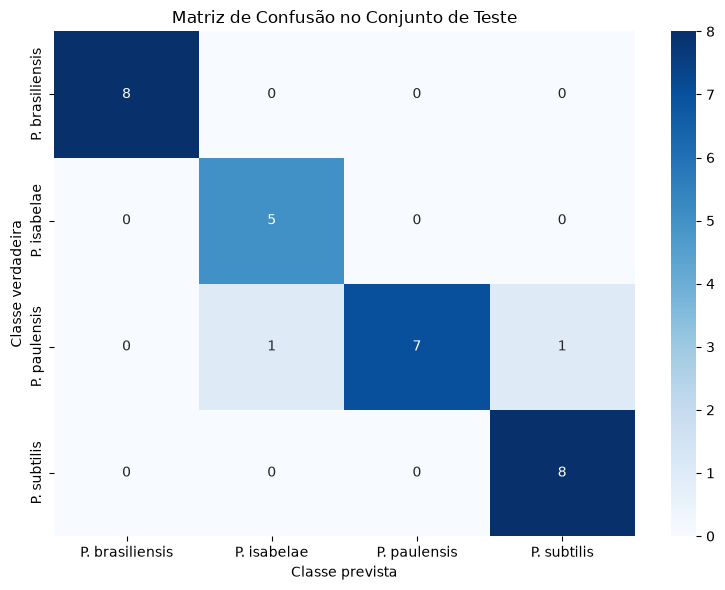

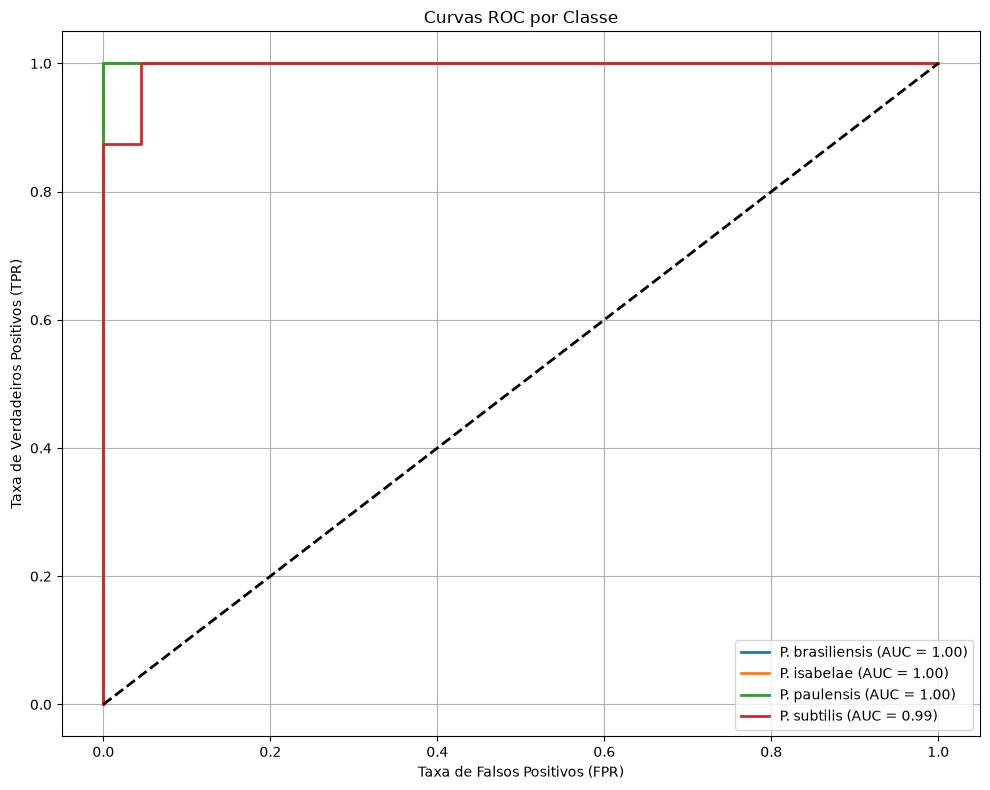

In [ ]:
test_model(model_mvcnn, test_loader, criterion)
os.makedirs("../models/gray/cross_validation", exist_ok=True)
torch.save(model_mvcnn.state_dict(), '../models/gray/cross_validation/modelo_resnet.pth')

Curva de perda de treinamento e validação para verificação de overfiting

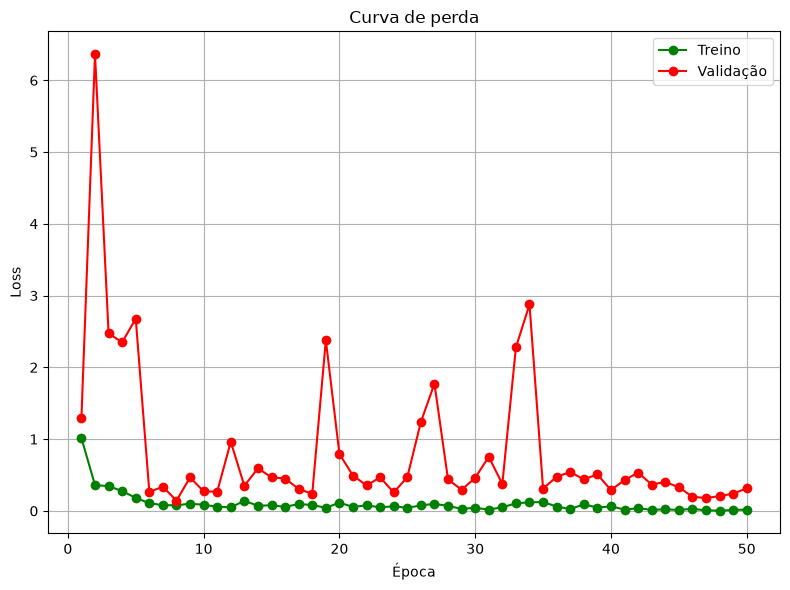

In [ ]:
plt.figure(figsize=(8, 6))

epochs = range(1, len(history.get_train_loss())+1)

plt.plot(epochs, history.get_train_loss(), label="Treino", color='green', marker='o')

plt.plot(epochs, history.get_val_loss(), label="Validação", color='red', marker='o')
plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Curva de perda")
plt.tight_layout()
plt.legend()
plt.grid(True)
plt.show()

Curva de acurácia do treinamento e validação para verificar overfiting

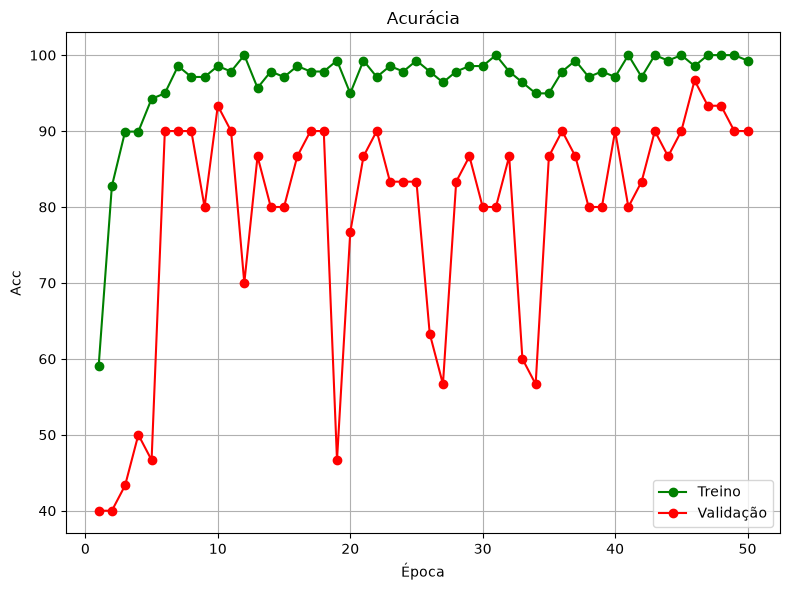

In [ ]:
plt.figure(figsize=(8, 6))

epoch = range(1, len(history.get_train_loss())+1)
plt.plot(epoch, history.get_train_acc(), label="Treino", color='green', marker='o')
plt.plot(epoch, history.get_val_acc(), label="Validação", color='red', marker='o')
plt.xlabel("Época")
plt.ylabel("Acc")
plt.title("Acurácia")
plt.tight_layout()
plt.legend()
plt.grid(True)
plt.show()

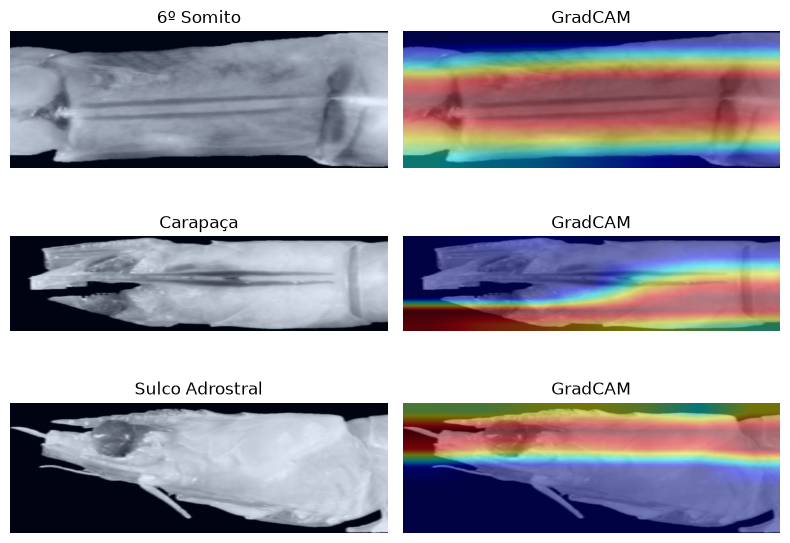

In [24]:
plot_gradcam(model_mvcnn,test_dataset ,4)